In [1]:
import mdtraj as md
import numpy as np
import matplotlib.pyplot as plt
import pickle
import os
import concurrent.futures


gleap_target = md.load("../20250801_FUS-RRM/2_md-preparation-2/gleap.target.gro")
atom_indices_protein = gleap_target.topology.select("resid 23 to 126")
atom_indices_rna     = gleap_target.topology.select("resid  0 to  22")
atom_indices_rna_docking_surface = gleap_target.topology.select("resid 7 to 16")
atom_index_protein_min = min(atom_indices_protein)

pickle_dir = "./pickle-cache/interactions_charge-attraction"


def calculate_interactions(xtc):
    atom_indices_charged = {
        "protein": {
            "positive": set(atom_indices_protein) & set(xtc.topology.select("(rescode R and (name NH1 or name NH2)) or (rescode K and name NZ) or (resname HIP and (name ND1 or name NE2))")),
            "negative": set(atom_indices_protein) & set(xtc.topology.select("(rescode D and (name OD1 or name OD2)) or (rescode E and (name OE1 or name OE2))")),
        },
        "rna": {
            "positive": [],
            "negative": set(atom_indices_rna) & set(xtc.topology.select("name OP1 or name OP2")),
        }
    }
    _interactions = np.zeros((len(atom_indices_protein), len(atom_indices_rna), xtc.n_frames))
    for atom_index_protein in atom_indices_charged["protein"]["positive"]:
        for atom_index_rna in atom_indices_charged["rna"]["negative"]:
            distances = np.linalg.norm(xtc.xyz[:, atom_index_protein]-xtc.xyz[:, atom_index_rna], axis=1)
            _interactions[atom_index_protein-atom_index_protein_min][atom_index_rna][np.where(distances < 0.3)[0]] += 1
    return _interactions
    

if True:
    def worker(trial):
        print(trial, "start")
        if trial == "cmd":
            interactions = np.zeros((5, len(atom_indices_protein), len(atom_indices_rna), 1800))
            for trial_cmd in range(5):
                xtc = md.load(f"../20250801_FUS-RRM/6_cmd-{trial_cmd+1}/cmd.skip10.whole.target.pbc.xtc", top=gleap_target)[2001::10]
                interactions[trial_cmd] = calculate_interactions(xtc)

            nonzero_indices = interactions.nonzero()
            nonzero_values  = interactions[nonzero_indices]
            pickle.dump([nonzero_indices, nonzero_values], open(f"{pickle_dir}/cmd_interactions.pickle", "wb"))

        else:
            interactions = np.zeros((len(atom_indices_protein), len(atom_indices_rna), 120))
            xtc = md.load(f"../20250801_FUS-RRM/7_pacs-1/trial{trial+1:03}/prd.target.trjcat-all.pbc.skip10.xtc", top=gleap_target)[::10]
            coms_protein             = md.compute_center_of_mass(xtc.atom_slice(atom_indices_protein))
            coms_rna_docking_surface = md.compute_center_of_mass(xtc.atom_slice(atom_indices_rna_docking_surface))
            com_distances = np.linalg.norm(coms_rna_docking_surface-coms_protein, axis=1)
            com_distances_binned = (com_distances*10).astype(int)

            _interactions = calculate_interactions(xtc)
            for timestep, com_distance_binned in enumerate(com_distances_binned):
                interactions[:, :, com_distance_binned] += _interactions[:, :, timestep]

            nonzero_indices = interactions.nonzero()
            nonzero_values  = interactions[nonzero_indices]
            pickle.dump([nonzero_indices, nonzero_values], open(f"{pickle_dir}/pacs_interactions_{trial}.pickle", "wb"))
            pickle.dump(np.bincount(com_distances_binned, minlength=120), open(f"{pickle_dir}/pacs_com_distances_bincount_{trial}.pickle", "wb"))
        print(trial, "completed")

    if not os.path.exists(pickle_dir):
        os.mkdir(pickle_dir)
    trials = ["cmd"]
    trials.extend(range(50))
    for _ in concurrent.futures.ProcessPoolExecutor(max_workers=2).map(worker, trials):
        pass


cmd_interactions = np.zeros((5, len(atom_indices_protein), len(atom_indices_rna), 1800))
nonzero_indices, nonzero_values = pickle.load(open(f"{pickle_dir}/cmd_interactions.pickle", "rb"))
cmd_interactions[nonzero_indices] = nonzero_values

pacs_interactions = np.zeros((50, len(atom_indices_protein), len(atom_indices_rna), 120))
pacs_com_distances_bincount = np.zeros((50, 120))
for trial in range(len(pacs_interactions)):
    nonzero_indices, nonzero_values = pickle.load(open(f"{pickle_dir}/pacs_interactions_{trial}.pickle", "rb"))
    pacs_interactions[trial][nonzero_indices] = nonzero_values
    pacs_com_distances_bincount[trial] = pickle.load(open(f"{pickle_dir}/pacs_com_distances_bincount_{trial}.pickle", "rb"))

pacs_interactions /= pacs_com_distances_bincount[:, np.newaxis, np.newaxis, :]
del pacs_com_distances_bincount

cmd0  startstart

0 completed
1 start
cmd completed
2 start
2 completed
3 start
1 completed
4 start
3 completed
5 start
4 completed
6 start
5 completed
7 start
6 completed
8 start
7 completed
9 start
9 completed
10 start
10 completed
11 start
8 completed
12 start
12 completed
13 start
11 completed
14 start
14 completed
15 start
13 completed
16 start
15 completed
17 start
16 completed
18 start
17 completed
19 start
18 completed
20 start
19 completed
21 start
20 completed
22 start
21 completed
23 start
22 completed
24 start
23 completed
25 start
24 completed
26 start
25 completed
27 start
26 completed
28 start
27 completed
29 start
28 completed
30 start
29 completed
31 start
31 completed
start32 
30 completed
33 start
33 completed
34 start
32 completed
35 start
34 completed
36 start
36 completed
37 start
35 completed
38 start
37 completed
39 start
38 completed

40 start40 completed
41 start
39 completed
42 start
41 completed
43 start
42 completed
44 start
43 completed
45 start
44 complet

/tmp/ipykernel_1831905/2165665085.py:87: RuntimeWarning: invalid value encountered in divide
  pacs_interactions /= pacs_com_distances_bincount[:, np.newaxis, np.newaxis, :]


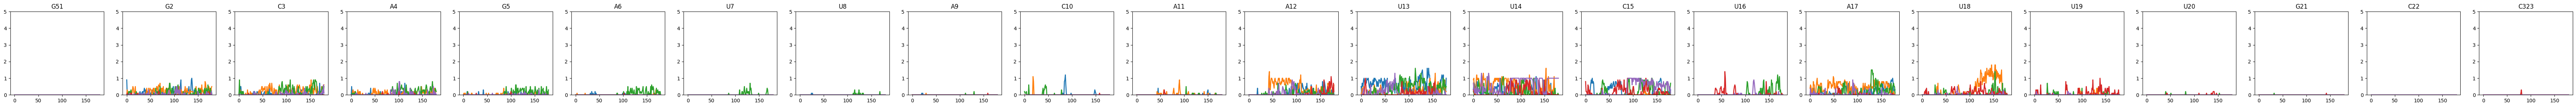

In [2]:
YMAX = 5

fig, ax = plt.subplots(1,23)
fig.set_size_inches(92, 3)

for residue_index_rna in range(0, 23):
    atom_indices_rna_residue = gleap_target.topology.select(f"resid {residue_index_rna}")
    atom_index_rna_residue_min = min(atom_indices_rna_residue)
    atom_index_rna_residue_max = max(atom_indices_rna_residue)

    for trial in range(len(cmd_interactions)):
        ax[residue_index_rna].plot(cmd_interactions[trial, :, atom_index_rna_residue_min:atom_index_rna_residue_max+1, :].sum(axis=(0, 1)).reshape(-1, 10).mean(axis=1), linewidth=2)

    ax[residue_index_rna].set_title(gleap_target.topology.residue(residue_index_rna))
    ax[residue_index_rna].set_ylim(0, YMAX)

U13-OP1-ARG76-NH2 0.1615798922800718 0.004022526146419952
U13-OP2-ARG76-NH2 0.1526032315978456 0.029766693483507644
U14-OP1-ARG120-NH1 0.08258527827648116 0.13917940466613032
U14-OP2-LYS82-NZ 0.06642728904847396 0.2341110217216412
C15-OP1-ARG120-NH2 0.08976660682226212 0.13113435237329044


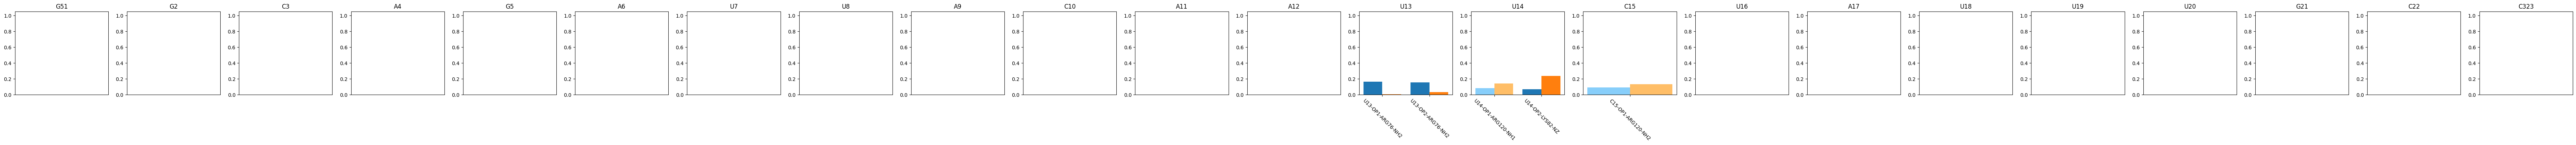

In [3]:
def make_label_protein(atom):
    return f"{atom.residue.name}{atom.residue.index}-{atom.name}"
    return f"{atom.residue.name}{atom.residue.index+252}-{atom.name}"


atom_indices_protein_rgion = {
    "rrm": list(gleap_target.topology.select("resid  24 to 116")),
    "rgg": list(gleap_target.topology.select("resid 117 to 125")),
}

colors = [
    {
        "rrm": "tab:blue",
        "rgg": "lightskyblue",
    },
    {
        "rrm": "tab:orange",
        "rgg": "#FFBE67",
    },
]

FRACTION_THRESHOLD = 0.1

fig, ax = plt.subplots(1, 23)
fig.set_size_inches(92, 3)

# cmd_interactions_transpose_concat = np.concatenate(cmd_interactions.transpose(0, 3, 1, 2))
cmd_interactions_transpose_concat = np.concatenate(cmd_interactions[:, :, :, ::5].transpose(0, 3, 1, 2))

metastabled_trajs_concat = pickle.load(open(f"./pickle-cache/pca_tetranucl_all/metastabled_trajs_concat_2.pickle", "rb"))[::50]
for residue_index_rna in range(0, 23):
    atom_idices_rna_residue = gleap_target.topology.select(f"resid {residue_index_rna}")
    atom_index_rna_residue_min = min(atom_idices_rna_residue)
    atom_index_rna_residue_max = max(atom_idices_rna_residue)

    i_bar = 0
    xticks = []
    for atom_index_rna_residue in range(atom_index_rna_residue_min, atom_index_rna_residue_max+1):
        for atom_index_protein in atom_indices_protein:
            fraction_0 = cmd_interactions_transpose_concat[metastabled_trajs_concat==0, atom_index_protein-atom_index_protein_min, atom_index_rna_residue].mean()
            fraction_1 = cmd_interactions_transpose_concat[metastabled_trajs_concat==1, atom_index_protein-atom_index_protein_min, atom_index_rna_residue].mean()

            region = "rrm"
            if atom_index_protein in atom_indices_protein_rgion["rgg"]:
                region = "rgg"
            if fraction_0 > FRACTION_THRESHOLD or fraction_1 > FRACTION_THRESHOLD:
                ax[residue_index_rna].bar(i_bar-0.2, fraction_0, width=0.4, color=colors[0][region])
                ax[residue_index_rna].bar(i_bar+0.2, fraction_1, width=0.4, color=colors[1][region])
                i_bar += 1
                xticks.append(f"{gleap_target.topology.atom(atom_index_rna_residue)}-{make_label_protein(gleap_target.topology.atom(atom_index_protein))}")
                print(f"{gleap_target.topology.atom(atom_index_rna_residue)}-{make_label_protein(gleap_target.topology.atom(atom_index_protein))}", fraction_0, fraction_1)

    ax[residue_index_rna].set_title(gleap_target.topology.residue(residue_index_rna))
    ax[residue_index_rna].set_ylim(0, 1.05)
    ax[residue_index_rna].set_xticks(range(len(xticks)), xticks, rotation=-45)

del cmd_interactions_transpose_concat

G2-OP1-LYS60-NZ 0.0466786355475763 0.004022526146419952
G2-OP1-LYS63-NZ 0.01436265709156194 0.019308125502815767
G2-OP1-LYS64-NZ 0.0017953321364452424 0.0008045052292839903
G2-OP2-LYS60-NZ 0.0 0.003218020917135961
G2-OP2-LYS63-NZ 0.04129263913824058 0.030571198712791632
G2-OP2-LYS64-NZ 0.00718132854578097 0.007240547063555913
C3-OP1-LYS60-NZ 0.02333931777378815 0.0
C3-OP1-LYS63-NZ 0.06642728904847396 0.02574416733708769
C3-OP1-LYS64-NZ 0.0017953321364452424 0.002413515687851971
C3-OP2-LYS60-NZ 0.017953321364452424 0.0
C3-OP2-LYS63-NZ 0.06463195691202872 0.038616251005631534
C3-OP2-LYS64-NZ 0.003590664272890485 0.004827031375703942
A4-OP1-LYS60-NZ 0.003590664272890485 0.0
A4-OP1-LYS63-NZ 0.03231597845601436 0.0008045052292839903
A4-OP1-LYS64-NZ 0.0 0.003218020917135961
A4-OP2-LYS63-NZ 0.05565529622980251 0.016090104585679808
A4-OP2-LYS64-NZ 0.012567324955116697 0.015285599356395816
G5-OP1-LYS63-NZ 0.010771992818671455 0.0
G5-OP1-LYS64-NZ 0.003590664272890485 0.0
G5-OP2-LYS63-NZ 0.014362

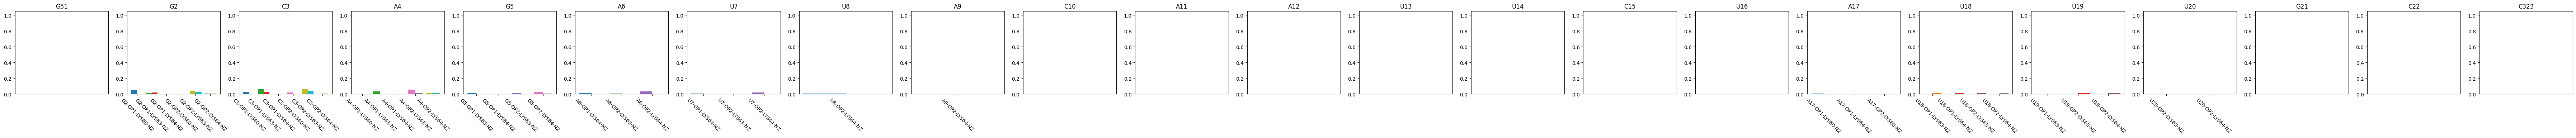

In [4]:
fig, ax = plt.subplots(1, 23)
fig.set_size_inches(92, 3)

# cmd_interactions_transpose_concat = np.concatenate(cmd_interactions.transpose(0, 3, 1, 2))
cmd_interactions_transpose_concat = np.concatenate(cmd_interactions[:, :, :, ::5].transpose(0, 3, 1, 2))

metastabled_trajs_concat = pickle.load(open(f"./pickle-cache/pca_tetranucl_all/metastabled_trajs_concat_2.pickle", "rb"))[::50]
for residue_index_rna in range(0, 23):
    atom_idices_rna_residue = gleap_target.topology.select(f"resid {residue_index_rna}")
    atom_index_rna_residue_min = min(atom_idices_rna_residue)
    atom_index_rna_residue_max = max(atom_idices_rna_residue)

    i_bar = 0
    xticks = []
    for atom_index_rna_residue in range(atom_index_rna_residue_min, atom_index_rna_residue_max+1):
        for atom_index_protein in atom_indices_protein:
            if not gleap_target.topology.atom(atom_index_protein).residue.index in [60, 63, 64]:
                continue
            fraction_0 = cmd_interactions_transpose_concat[metastabled_trajs_concat==0, atom_index_protein-atom_index_protein_min, atom_index_rna_residue].mean()
            fraction_1 = cmd_interactions_transpose_concat[metastabled_trajs_concat==1, atom_index_protein-atom_index_protein_min, atom_index_rna_residue].mean()

            if fraction_0 > 0 or fraction_1 > 0:
                ax[residue_index_rna].bar(i_bar-0.2, fraction_0, width=0.4)
                ax[residue_index_rna].bar(i_bar+0.2, fraction_1, width=0.4)
                i_bar += 1
                xticks.append(f"{gleap_target.topology.atom(atom_index_rna_residue)}-{make_label_protein(gleap_target.topology.atom(atom_index_protein))}")
                print(f"{gleap_target.topology.atom(atom_index_rna_residue)}-{make_label_protein(gleap_target.topology.atom(atom_index_protein))}", fraction_0, fraction_1)

    ax[residue_index_rna].set_title(gleap_target.topology.residue(residue_index_rna))
    ax[residue_index_rna].set_ylim(0, 1.05)
    ax[residue_index_rna].set_xticks(range(len(xticks)), xticks, rotation=-45)

del cmd_interactions_transpose_concat

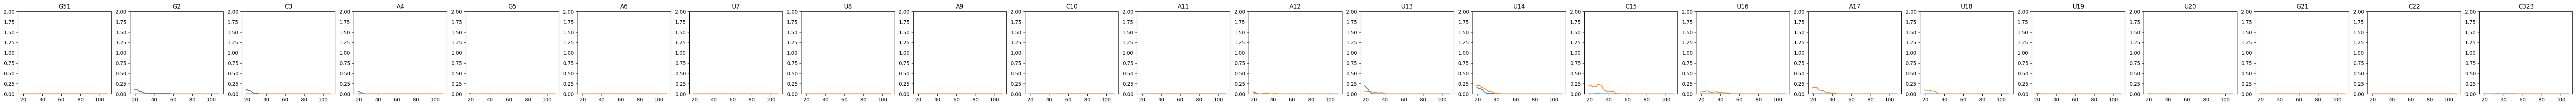

In [5]:
fig, ax = plt.subplots(1, 23)
fig.set_size_inches(92, 3)

pacs_interactions_trial_mean = pacs_interactions.mean(axis=0)

for residue_index_rna in range(0, 23):
    atom_idices_rna_residue = gleap_target.topology.select(f"resid {residue_index_rna}")

    pacs_interactions_trial_mean_rna_sum = pacs_interactions_trial_mean[:, atom_idices_rna_residue].sum(axis=1)

    ax[residue_index_rna].plot(pacs_interactions_trial_mean_rna_sum[atom_indices_protein_rgion["rrm"]-atom_index_protein_min].sum(axis=0))
    ax[residue_index_rna].plot(pacs_interactions_trial_mean_rna_sum[atom_indices_protein_rgion["rgg"]-atom_index_protein_min].sum(axis=0))

    ax[residue_index_rna].set_title(gleap_target.topology.residue(residue_index_rna))
    ax[residue_index_rna].set_ylim(0, 2)

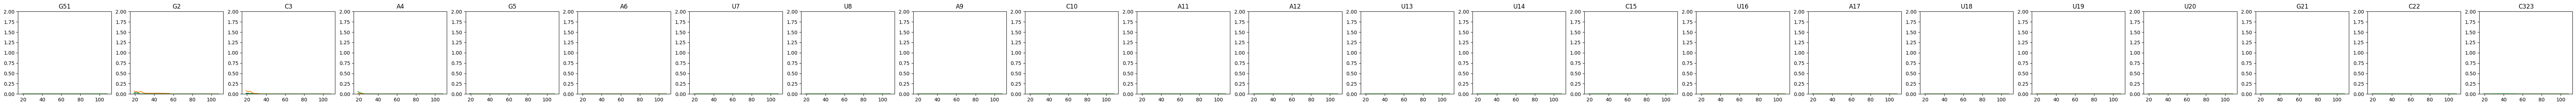

In [6]:
fig, ax = plt.subplots(1, 23)
fig.set_size_inches(92, 3)

pacs_interactions_trial_mean = pacs_interactions.mean(axis=0)

for residue_index_rna in range(0, 23):
    atom_idices_rna_residue = gleap_target.topology.select(f"resid {residue_index_rna}")

    pacs_interactions_trial_mean_rna_sum = pacs_interactions_trial_mean[:, atom_idices_rna_residue].sum(axis=1)

    for residue_index_protein_kk in [60, 63, 64]:
        atom_indices_protein_kk_residue = np.array([atom.index for atom in gleap_target.topology.residue(residue_index_protein_kk).atoms])
        ax[residue_index_rna].plot(pacs_interactions_trial_mean_rna_sum[atom_indices_protein_kk_residue-atom_index_protein_min].sum(axis=0))

    ax[residue_index_rna].set_title(gleap_target.topology.residue(residue_index_rna))
    ax[residue_index_rna].set_ylim(0, 2)

In [7]:
fig, ax = plt.subplots(len(pacs_interactions), 23)
fig.set_size_inches(92, 3*len(pacs_interactions))

for trial in range(len(pacs_interactions)):
    for residue_index_rna in range(0, 23):
        atom_idices_rna_residue = gleap_target.topology.select(f"resid {residue_index_rna}")

        pacs_interactions_rna_sum = pacs_interactions[trial, :, atom_idices_rna_residue].sum(axis=0)

        ax[trial, residue_index_rna].plot(pacs_interactions_rna_sum[atom_indices_protein_rgion["rrm"]-atom_index_protein_min].sum(axis=0))
        ax[trial, residue_index_rna].plot(pacs_interactions_rna_sum[atom_indices_protein_rgion["rgg"]-atom_index_protein_min].sum(axis=0))

        ax[trial, residue_index_rna].set_title(f"{trial}-{gleap_target.topology.residue(residue_index_rna)}")
        ax[trial, residue_index_rna].set_ylim(0, 2)

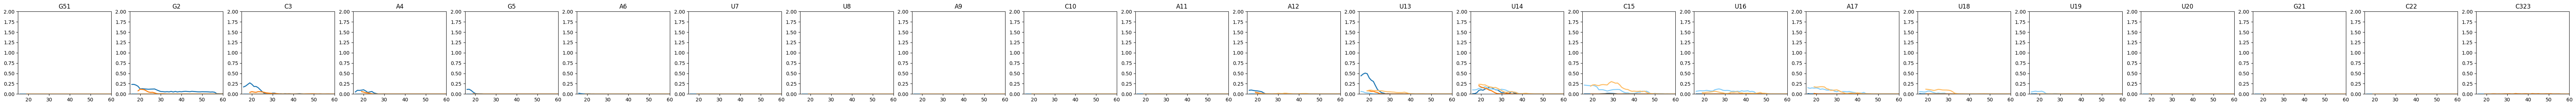

In [8]:
trial_groups_initial = [
    [0, 1, 2, 3, 4, 5, 6, 7, 9, 24, 25, 26, 27, 28, 29],
    [],
]
trial_groups_initial[1] = [trial for trial in range(50) if not trial in trial_groups_initial[0]]


fig, ax = plt.subplots(1, 23)
fig.set_size_inches(92, 3)

for i_trial_group, trial_group_trials in enumerate(trial_groups_initial):
    pacs_interactions_trial_sum = np.zeros((len(atom_indices_protein), len(atom_indices_rna), 120))
    for trial in trial_group_trials:
        pacs_interactions_trial_sum += pacs_interactions[trial]
    pacs_interactions_trial_mean = pacs_interactions_trial_sum / len(trial_group_trials)
    
    for residue_index_rna in range(0, 23):
        atom_idices_rna_residue = gleap_target.topology.select(f"resid {residue_index_rna}")
    
        pacs_interactions_trial_mean_rna_sum = pacs_interactions_trial_mean[:, atom_idices_rna_residue].sum(axis=1)
    
        ax[residue_index_rna].plot(pacs_interactions_trial_mean_rna_sum[atom_indices_protein_rgion["rrm"]-atom_index_protein_min].sum(axis=0), c=colors[i_trial_group]["rrm"], linestyle="-", linewidth=2)
        ax[residue_index_rna].plot(pacs_interactions_trial_mean_rna_sum[atom_indices_protein_rgion["rgg"]-atom_index_protein_min].sum(axis=0), c=colors[i_trial_group]["rgg"], linestyle="-", linewidth=2)
    
        ax[residue_index_rna].set_title(gleap_target.topology.residue(residue_index_rna))
        ax[residue_index_rna].set_xlim(15, 60)
        ax[residue_index_rna].set_ylim(0, 2)

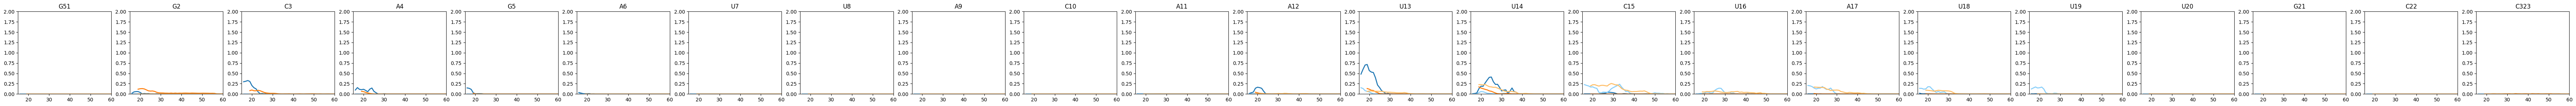

In [9]:
trial_groups_initial = [
    [4, 7, 25, 26, 28, 29],
    [],
]
trial_groups_initial[1] = [trial for trial in range(50) if not trial in trial_groups_initial[0]]


fig, ax = plt.subplots(1, 23)
fig.set_size_inches(92, 3)

for i_trial_group, trial_group_trials in enumerate(trial_groups_initial):
    pacs_interactions_trial_sum = np.zeros((len(atom_indices_protein), len(atom_indices_rna), 120))
    for trial in trial_group_trials:
        pacs_interactions_trial_sum += pacs_interactions[trial]
    pacs_interactions_trial_mean = pacs_interactions_trial_sum / len(trial_group_trials)
    
    for residue_index_rna in range(0, 23):
        atom_idices_rna_residue = gleap_target.topology.select(f"resid {residue_index_rna}")
    
        pacs_interactions_trial_mean_rna_sum = pacs_interactions_trial_mean[:, atom_idices_rna_residue].sum(axis=1)
    
        ax[residue_index_rna].plot(pacs_interactions_trial_mean_rna_sum[atom_indices_protein_rgion["rrm"]-atom_index_protein_min].sum(axis=0), c=colors[i_trial_group]["rrm"], linestyle="-", linewidth=2)
        ax[residue_index_rna].plot(pacs_interactions_trial_mean_rna_sum[atom_indices_protein_rgion["rgg"]-atom_index_protein_min].sum(axis=0), c=colors[i_trial_group]["rgg"], linestyle="-", linewidth=2)
    
        ax[residue_index_rna].set_title(gleap_target.topology.residue(residue_index_rna))
        ax[residue_index_rna].set_xlim(15, 60)
        ax[residue_index_rna].set_ylim(0, 2)